# 📈 Linear Regression from Scratch

**Goal:** understand linear regression by building it myself with NumPy, two ways, and checking that my results match scikit-learn.

**Task:** predict a car's fuel efficiency (**miles per gallon**) from its weight, horsepower, engine size, year and origin.

1. Normal equation (closed-form solution)
2. Gradient descent (iterative optimisation)
3. Comparison with `sklearn.linear_model.LinearRegression`
4. Evaluation: RMSE, MAE, R², residual analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")
np.random.seed(42)
import os
os.makedirs("images", exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 1. Load and explore the data

In [2]:
cars = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv")
print(cars.shape)
cars.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
print(cars.isna().sum()[cars.isna().sum() > 0])
cars = cars.dropna()          # only 6 rows with missing horsepower
cars.describe().round(1)

horsepower    6
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,392.0,392.0,392.0,392.0,392.0,392.0,392.0
mean,23.4,5.5,194.4,104.5,2977.6,15.5,76.0
std,7.8,1.7,104.6,38.5,849.4,2.8,3.7
min,9.0,3.0,68.0,46.0,1613.0,8.0,70.0
25%,17.0,4.0,105.0,75.0,2225.2,13.8,73.0
50%,22.8,4.0,151.0,93.5,2803.5,15.5,76.0
75%,29.0,8.0,275.8,126.0,3614.8,17.0,79.0
max,46.6,8.0,455.0,230.0,5140.0,24.8,82.0


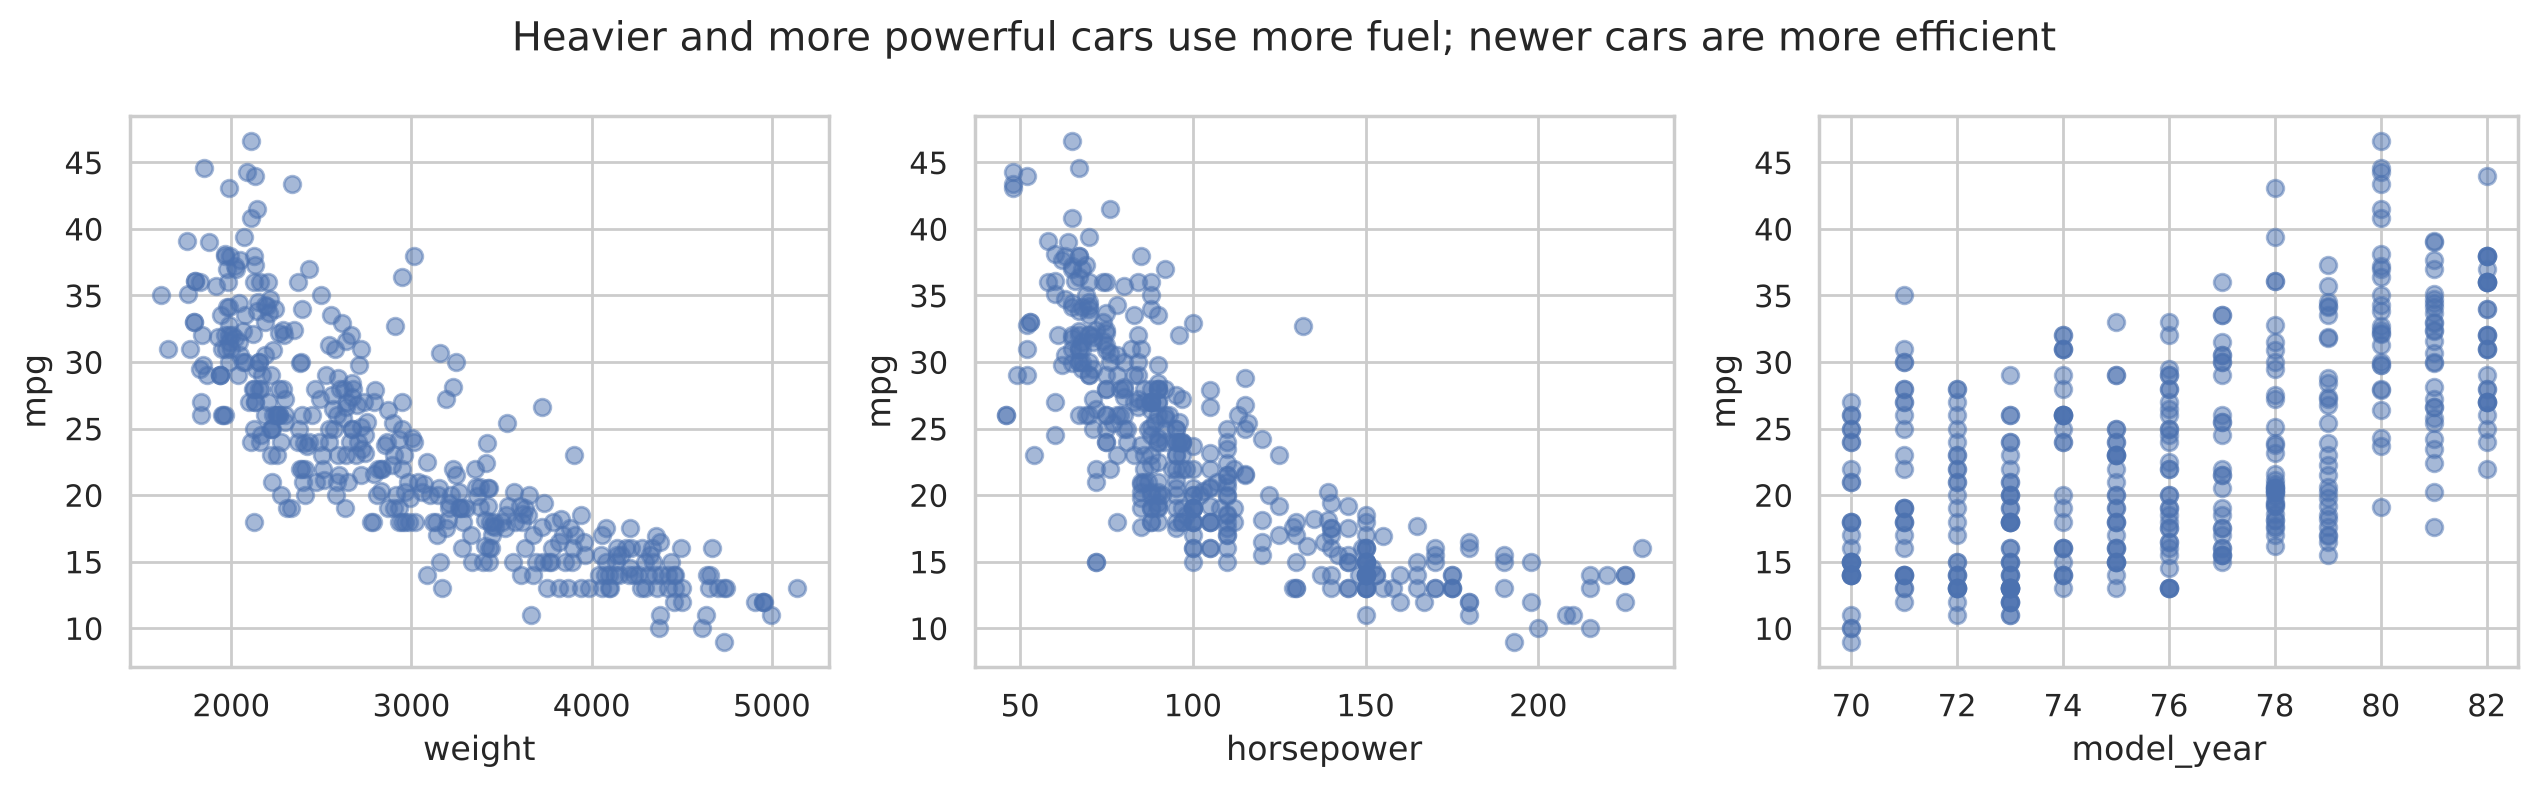

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["weight", "horsepower", "model_year"]):
    ax.scatter(cars[col], cars["mpg"], alpha=.5)
    ax.set_xlabel(col); ax.set_ylabel("mpg")
fig.suptitle("Heavier and more powerful cars use more fuel; newer cars are more efficient")
savefig("eda_scatter")

## 2. Prepare features
- One-hot encode `origin` (categorical)
- **Standardise** numeric features (mean 0, std 1) so gradient descent converges well
- Add a column of 1s for the intercept (bias) term

In [5]:
features = ["weight", "horsepower", "displacement", "model_year"]
X = pd.get_dummies(cars[features + ["origin"]], columns=["origin"], drop_first=True, dtype=float)
y = cars["mpg"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mean, std = X_train[features].mean(), X_train[features].std()
X_train[features] = (X_train[features] - mean) / std
X_test[features] = (X_test[features] - mean) / std   # use TRAIN statistics only (no data leakage)

feature_names = list(X_train.columns)
add_bias = lambda A: np.c_[np.ones(len(A)), A]
Xtr, Xte = add_bias(X_train.values), add_bias(X_test.values)
print("Training matrix:", Xtr.shape, "| Test matrix:", Xte.shape)

Training matrix: (313, 7) | Test matrix: (79, 7)


## 3. Method 1: Normal equation

Linear regression minimises the squared error $\|y - X\beta\|^2$. Setting the derivative to zero gives

$$\hat\beta = (X^\top X)^{-1} X^\top y$$

I use `np.linalg.solve` instead of explicitly inverting the matrix (more numerically stable).

In [6]:
def fit_normal_equation(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

beta_ne = fit_normal_equation(Xtr, y_train)
beta_ne.round(3)

array([25.374, -5.34 , -0.934,  1.396,  2.888,  0.303, -2.845])

## 4. Method 2: Gradient descent

Instead of solving directly, start with $\beta = 0$ and repeatedly step downhill along the gradient of the mean squared error:

$$\nabla = \frac{2}{n} X^\top (X\beta - y), \qquad \beta \leftarrow \beta - \alpha \nabla$$

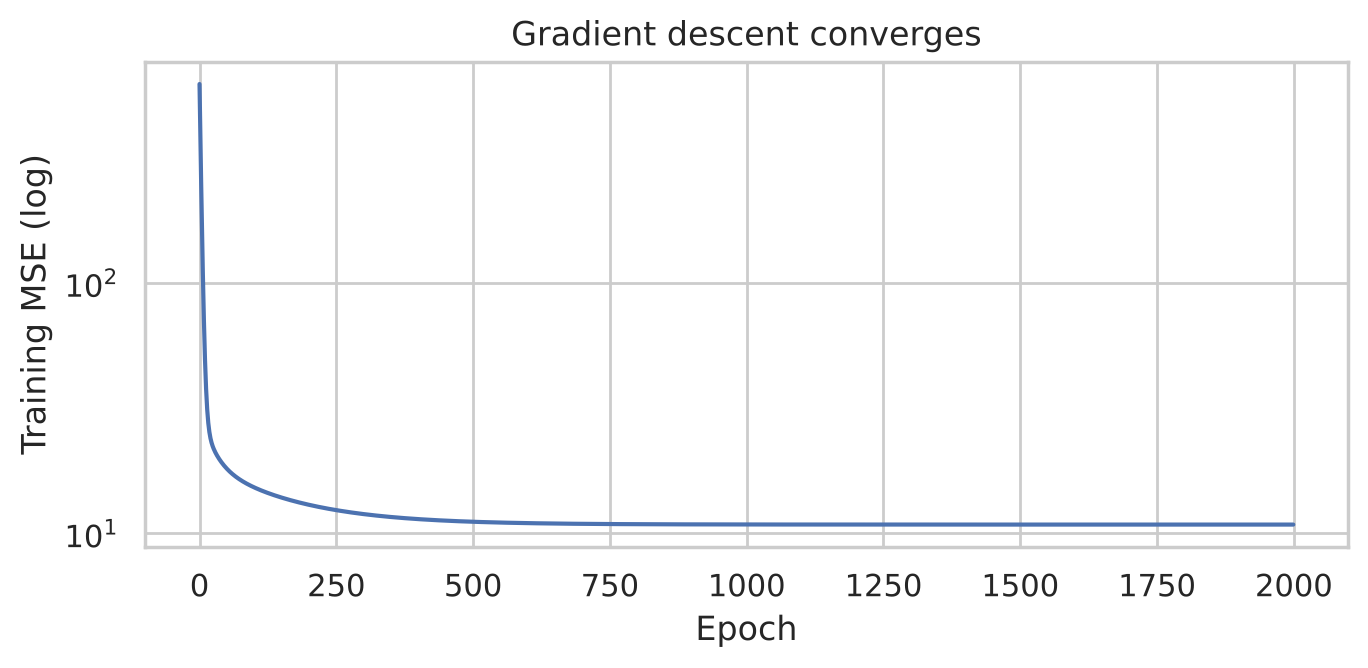

In [7]:
def fit_gradient_descent(X, y, lr=0.05, epochs=2000):
    beta = np.zeros(X.shape[1])
    history = []
    for _ in range(epochs):
        error = X @ beta - y
        history.append((error ** 2).mean())
        beta -= lr * (2 / len(y)) * X.T @ error
    return beta, history

beta_gd, history = fit_gradient_descent(Xtr, y_train)

plt.figure(figsize=(7, 3.5))
plt.plot(history); plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("Training MSE (log)")
plt.title("Gradient descent converges")
savefig("gd_convergence")

## 5. Compare with scikit-learn

In [8]:
sk = LinearRegression().fit(X_train, y_train)
beta_sk = np.r_[sk.intercept_, sk.coef_]

comparison = pd.DataFrame({"Normal equation": beta_ne, "Gradient descent": beta_gd, "scikit-learn": beta_sk},
                          index=["intercept"] + feature_names)
comparison.round(4)

,Normal equation,Gradient descent,scikit-learn
intercept,25.3742,25.3652,25.3742
weight,-5.3401,-5.3361,-5.3401
horsepower,-0.9339,-0.9323,-0.9339
displacement,1.3962,1.3888,1.3962
model_year,2.8882,2.8872,2.8882
origin_japan,0.3030,0.3119,0.3030
origin_usa,-2.8446,-2.8339,-2.8446


In [9]:
print("Max difference NE vs sklearn:", np.abs(beta_ne - beta_sk).max())
print("Max difference GD vs sklearn:", np.abs(beta_gd - beta_sk).max())

Max difference NE vs sklearn: 1.63202784619898e-14
Max difference GD vs sklearn: 0.010645351078024223


✅ All three methods give the same coefficients, so the from-scratch implementations are correct.

## 6. Evaluate on the test set (metrics also written from scratch)

In [10]:
def rmse(y, p): return np.sqrt(np.mean((y - p) ** 2))
def mae(y, p):  return np.mean(np.abs(y - p))
def r2(y, p):   return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

pred = Xte @ beta_ne
baseline = np.full_like(y_test, y_train.mean())      # always predict the average

pd.DataFrame({"Linear regression": [rmse(y_test, pred), mae(y_test, pred), r2(y_test, pred)],
              "Baseline (mean)":   [rmse(y_test, baseline), mae(y_test, baseline), r2(y_test, baseline)]},
             index=["RMSE (mpg)", "MAE (mpg)", "R²"]).round(3)

,Linear regression,Baseline (mean)
RMSE (mpg),3.293,7.185
MAE (mpg),2.481,5.881
R²,0.787,-0.011


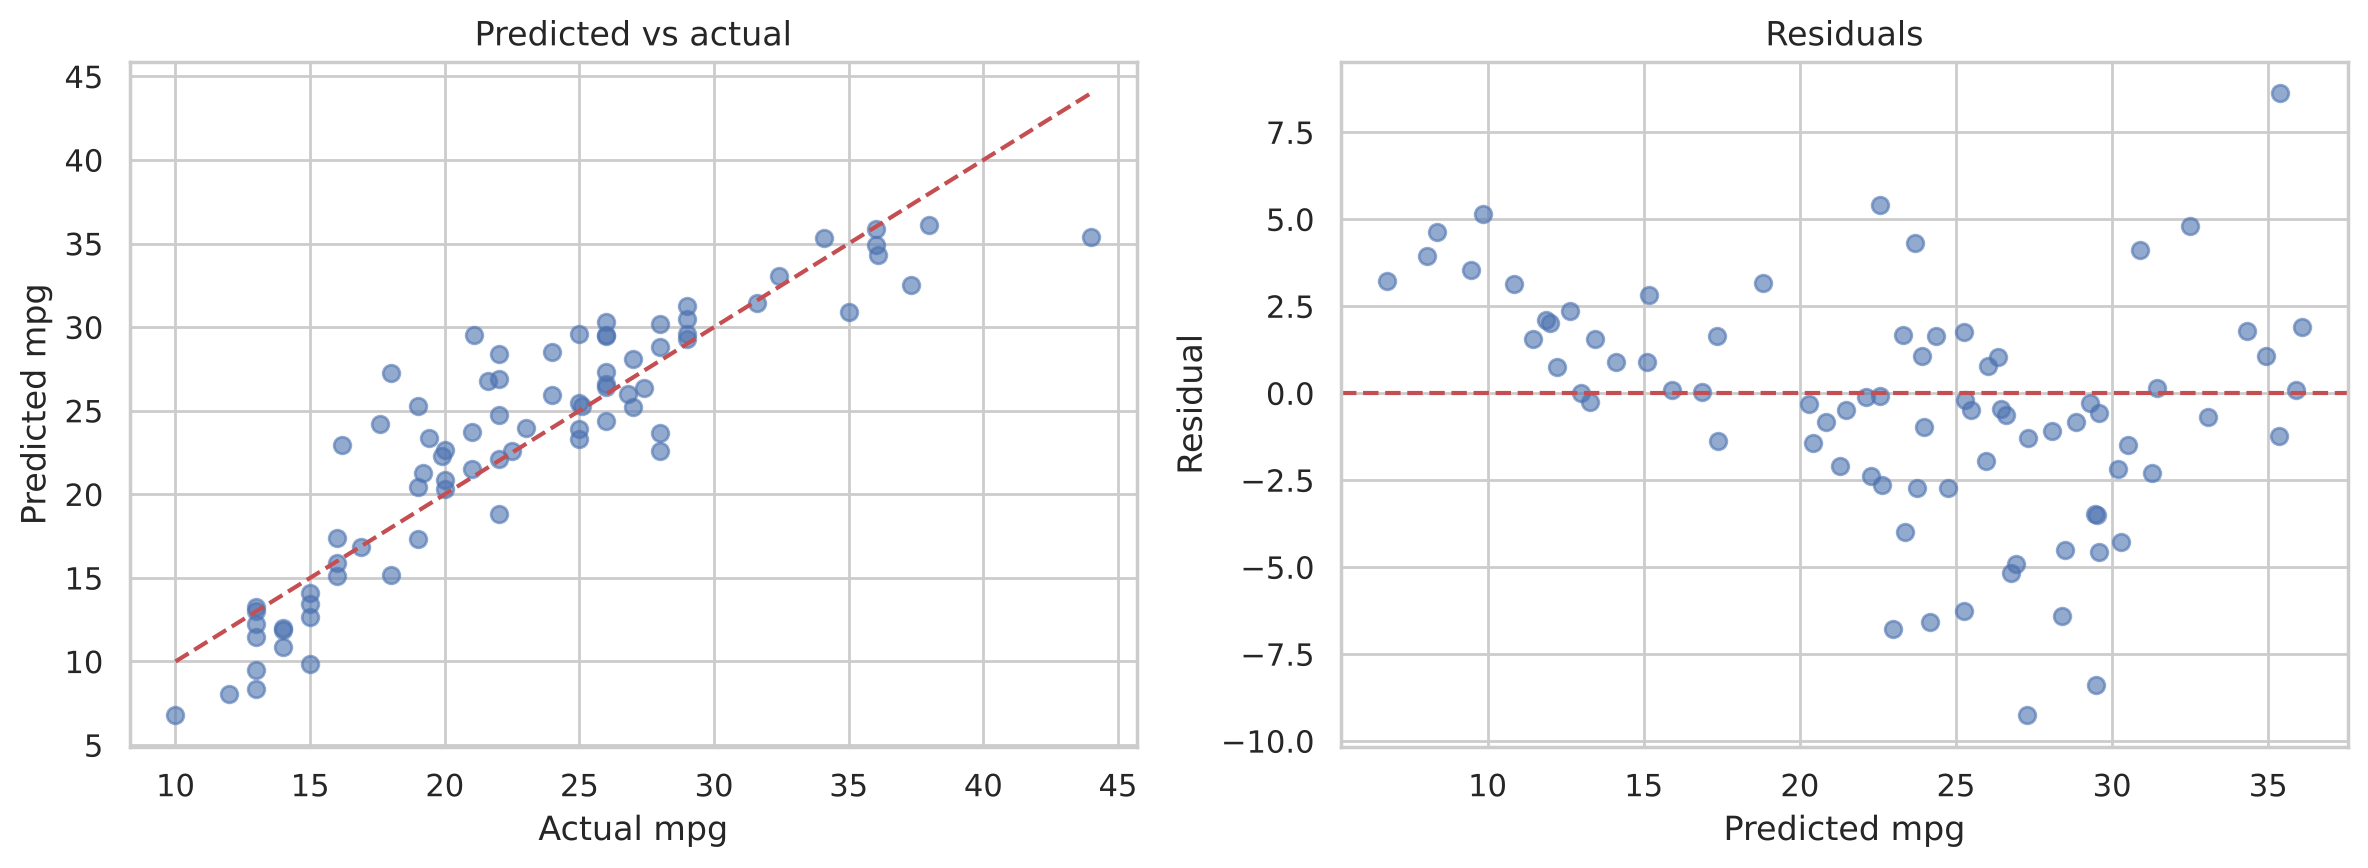

In [11]:
resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=.6)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("Actual mpg"); axes[0].set_ylabel("Predicted mpg")
axes[0].set_title("Predicted vs actual")
axes[1].scatter(pred, resid, alpha=.6); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted mpg"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals")
savefig("evaluation")

## 7. Interpret the model

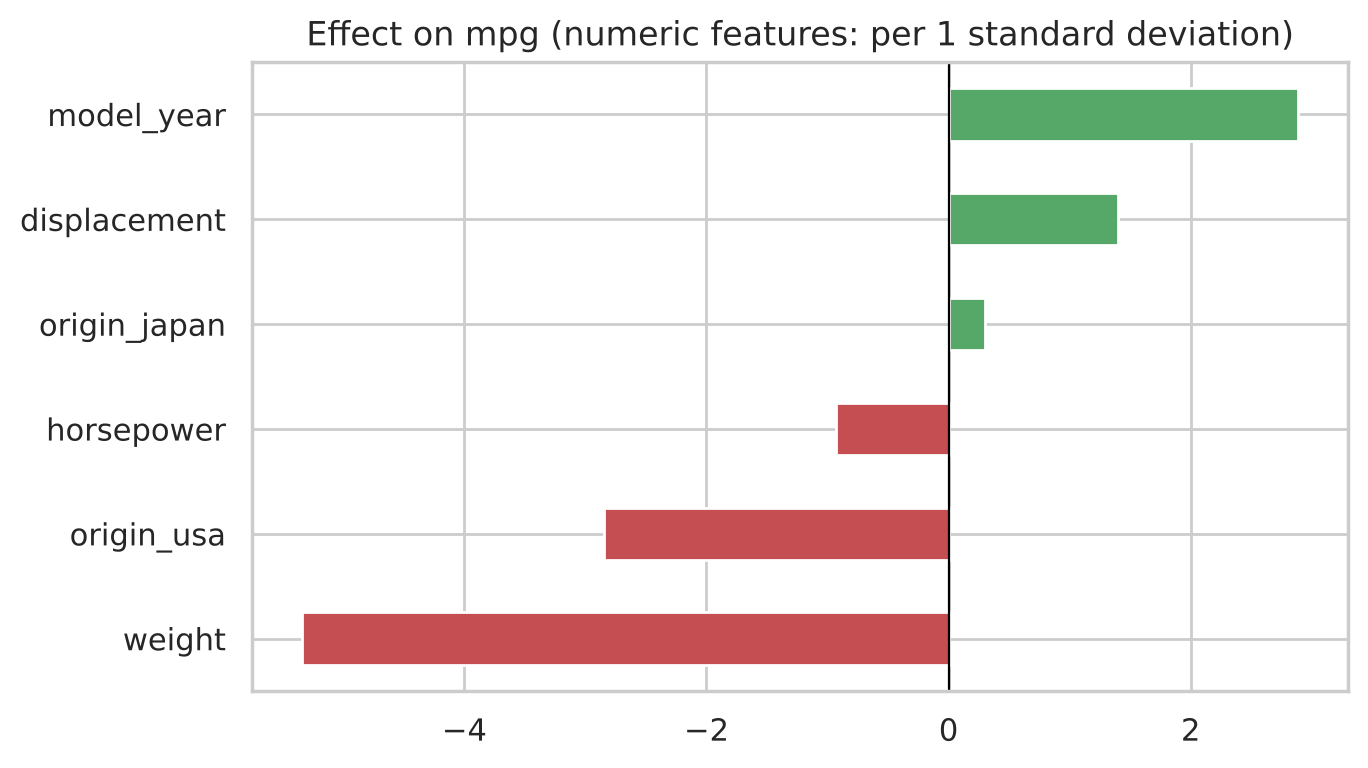

In [12]:
coefs = comparison["Normal equation"].drop("intercept").sort_values()
plt.figure(figsize=(7, 4))
coefs.plot(kind="barh", color=["#C44E52" if c < 0 else "#55A868" for c in coefs])
plt.axvline(0, color="black", lw=.8)
plt.title("Effect on mpg (numeric features: per 1 standard deviation)")
savefig("coefficients")

## Conclusions

- The model explains roughly **79 % of the variance** in fuel efficiency on unseen cars (R² = 0.79, RMSE ≈ 3.3 mpg) and is far better than the mean baseline.
- **Weight** is the strongest negative factor; **model year** is strongly positive (cars got more efficient over the 1970s–80s); US-built cars average ~2.8 mpg less than European ones with the same specs.
- **Displacement** gets a *positive* coefficient even though bigger engines use more fuel on their own: it is strongly correlated with weight and horsepower (multicollinearity), so individual coefficients must be interpreted carefully.
- The residual plot shows a slight **curve**: very efficient and very inefficient cars are under-predicted. The real relationship is somewhat non-linear, so a natural next step is adding polynomial features (e.g. weight²) or trying a log-transformed target.

**Skills shown:** linear algebra in NumPy, gradient descent, feature scaling without data leakage, model validation, and interpreting coefficients.